# Evolving a mono-green deck against a fixed gauntlet

This notebook runs one method end to end: a **genetic algorithm** over decklists,
scored by **actually playing games** against a fixed set of opponents.

It is the honest baseline for deckbuilding search. No training data, no surrogate
model, no assumptions about the shape of the objective — it evaluates the true
thing directly. Anything cleverer has to beat this to have bought you something.

**What you should not believe by the end.** The number this produces is a win
rate *against these five decks, piloted by a crude heuristic agent*. That is a
real, measurable quantity, and it is not the same as "this is a good deck". The
last two sections are about measuring the gap rather than papering over it.

The loop, concretely:

| Piece | What it is | Where it lives |
|---|---|---|
| Genome | integer vector of card counts, ≤4 each, summing to 60 | `cards.CandidatePool` |
| Fitness | win rate over N games vs a fixed gauntlet | `evaluate.match.MatchEvaluator` |
| Pilot | "play a land, cast the biggest thing, attack" | `engine.agents.CurveAgent` |
| Evolution | tournament select → crossover → mutate → repair | `search.genetic.GeneticSearch` |
| Budget | counted in simulated games, never wall clock | `search.budget.BudgetMeter` |

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
from collections import Counter

from manalab.cards.store import CardStore
from manalab.cards.model import Decklist
from manalab.engine import fidelity
from manalab.evaluate import gauntlet as G
from manalab.evaluate import pool as P
from manalab.evaluate.match import MatchEvaluator, GauntletDeck, gauntlet_fidelity
from manalab.search.genetic import GeneticSearch, repair, crossover, mutate, random_genome
from manalab.search.objective import WIN_RATE
from manalab.search.problem import Problem
from manalab.search.runner import run_optimizer

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

# The card store is a build artifact under the repo root; find it from wherever
# this notebook was launched rather than assuming a working directory.
REPO = Path.cwd()
while not (REPO / "data" / "cards.duckdb").exists() and REPO != REPO.parent:
    REPO = REPO.parent

store = CardStore(REPO / "data" / "cards.duckdb")
print(f"{store.count():,} cards in the store")

35,142 cards in the store


## 1. The pool — and what the engine is allowed to be trusted on

Mono-green is what makes this tractable: instead of thousands of cards the search
space is around a hundred, and green's cards are mostly *bodies*, which is the
part of Magic a crude combat engine actually models.

But "mono-green" is not enough of a filter. The engine does not execute rules
text, so a card whose text wins the game is, to the search, a vanilla creature
with the same stats. Optimising over those cards produces a confident, wrong
answer — so the pool is split in two.

`engine.fidelity` is the engine's account of its own blind spots. It lives in the
engine because the engine is the only thing that knows what it implements;
keeping the list anywhere else means a second copy that drifts.

In [2]:
pool = P.mono_color(store, "G", fmt="modern")

print(f"faithful pool : {pool.size:>5} cards   <- the search space")
print(f"text tier     : {len(pool.text_tier):>5} cards   <- playable, but text is ignored")
print()
print("why cards were set aside (the implement-next list):")
for reason, n in pool.gaps():
    print(f"  {n:>5}  {reason}")

faithful pool :   132 cards   <- the search space
text tier     :  3064 cards   <- playable, but text is ignored

why cards were set aside (the implement-next list):
   2174  rules text the engine does not execute
   1018  unimplemented keywords
    766  instant or sorcery; resolves with no effect
    394  non-creature permanent; sits on the battlefield inertly
     95  multi-faced; the engine plays only one side
     32  characteristic-defining power/toughness (a '*')
     29  land with text the engine ignores


In [3]:
# What "faithful" and "set aside" actually look like.
for name in ["Leatherback Baloth", "Llanowar Elves", "Craterhoof Behemoth",
             "Birds of Paradise", "Giant Growth"]:
    card = store.by_name(name)
    report = fidelity.assess(card)
    mark = "OK  " if report.faithful else "SET ASIDE"
    print(f"{mark} {name:<22} {'; '.join(report.reasons) or 'every word modelled'}")

OK   Leatherback Baloth     every word modelled
OK   Llanowar Elves         every word modelled
SET ASIDE Craterhoof Behemoth    rules text the engine does not execute
SET ASIDE Birds of Paradise      rules text the engine does not execute
SET ASIDE Giant Growth           instant or sorcery; resolves with no effect


Note **Birds of Paradise** is set aside: it adds mana of *any* colour, and the
engine only understands a source that taps for one fixed colour. Llanowar Elves
survives because "{T}: Add {G}" is exactly what the mana code does.

That distinction is the whole point of the split. Both are 1-mana 0/1 and 1/1
mana creatures; only one of them is modelled correctly.

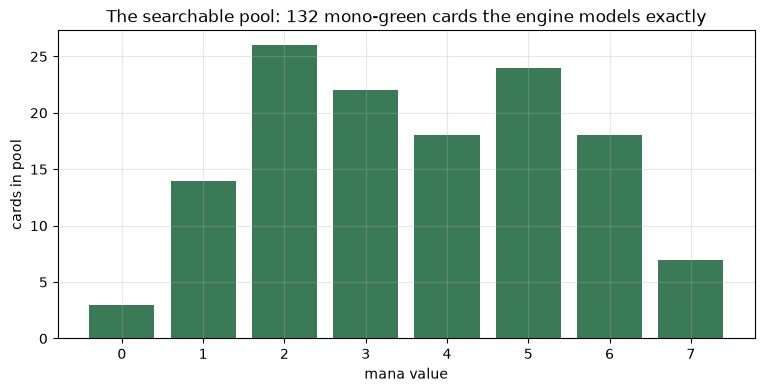

In [4]:
curve = Counter(c.cmc for c in pool.cards.values())
fig, ax = plt.subplots()
ax.bar(list(curve.keys()), list(curve.values()), color="#3b7a57")
ax.set_xlabel("mana value"); ax.set_ylabel("cards in pool")
ax.set_title(f"The searchable pool: {pool.size} mono-green cards the engine models exactly")
plt.show()

## 2. What the engine actually does in combat

Before trusting any win rate, it is worth seeing the measuring instrument move.

Combat keywords were added for this experiment: flying and reach gate blocking,
menace requires two blockers, trample spills excess damage, deathtouch makes one
point lethal, first and double strike split damage into two passes, and lifelink
gains life. Multiple creatures can block, which sounds obvious but was the single
biggest thing missing — with one blocker allowed per turn, "play the widest
board" wins every game for reasons that have nothing to do with Magic.

Here is a 3/3 with one keyword, played against a deck of plain 3/3s.

In [5]:
from manalab.cards.mana import parse_cost
from manalab.cards.model import Card

FOREST = store.by_name("Forest")

def body(*keywords):
    return Card("t", "Test Beater", parse_cost("{2}{G}"), "Creature - Test",
                power="3", toughness="3", keywords=frozenset(keywords))

def deck_of(card, lands=24):
    return tuple([FOREST] * lands + [card] * (60 - lands))

plain = GauntletDeck("plain 3/3", deck_of(body()))
control = MatchEvaluator(gauntlet=(plain,), cards={"Forest": FOREST, "Test Beater": body()})

print("a 3/3 with ... vs a deck of plain 3/3s (400 games each)\n")
for kws in [(), ("Trample",), ("Lifelink",), ("Deathtouch",), ("Flying",),
            ("First strike",), ("Double strike",)]:
    ev = MatchEvaluator(gauntlet=(plain,),
                        cards={"Forest": FOREST, "Test Beater": body(*kws)})
    r = ev.evaluate(Decklist({"Forest": 24, "Test Beater": 36}), n_games=400, seed=1)
    label = ", ".join(kws) or "(no keyword - a mirror)"
    lo, hi = r.ci95("win_rate")
    print(f"  {label:<22} {r.metrics['win_rate']:.3f}   95% CI [{lo:.3f}, {hi:.3f}]")

a 3/3 with ... vs a deck of plain 3/3s (400 games each)



  (no keyword - a mirror) 0.531   95% CI [0.493, 0.569]


  Trample                0.531   95% CI [0.493, 0.569]


  Lifelink               0.611   95% CI [0.580, 0.642]


  Deathtouch             0.677   95% CI [0.640, 0.715]


  Flying                 0.745   95% CI [0.703, 0.787]


  First strike           0.935   95% CI [0.911, 0.959]


  Double strike          0.945   95% CI [0.923, 0.967]


The mirror sits at ~0.5, which is the sanity check that matters: identical decks,
balanced for the play/draw advantage, must be a coin flip. Everything else is
measured against that baseline.

Trample reads as neutral here, and that is correct rather than broken — two 3/3s
trading leaves no excess damage to trample over. It only pays when the attacker
outsizes the blocker.

## 3. The gauntlet — the world a deck is judged against

Win rate is a *relative* quantity: it is always "against what?". Five archetypes,
built only from faithful cards, differing along the axis the engine represents —
how fast the board fills and how big it gets.

The gauntlet is **fixed**. If it changed as the search improved, "fitness went
up" would stop meaning anything, and we would be running a much harder
co-evolution experiment while believing we were running this one.

In [6]:
gauntlet = G.standard(pool)
evaluator = MatchEvaluator(gauntlet=gauntlet, cards=pool.cards)

blind = gauntlet_fidelity(gauntlet)
print(f"cards in the gauntlet the engine cannot model: {blind or 'none'}\n")

for deck in gauntlet:
    counts = Counter(c.name for c in deck.cards)
    lands = counts.get("Forest", 0)
    top = ", ".join(f"{n}x {name}" for name, n in counts.most_common(4) if name != "Forest")
    print(f"{deck.name:<10} {lands:>2} lands | {top}")

cards in the gauntlet the engine cannot model: none

aggro      20 lands | 4x Alpine Grizzly, 4x Gnottvold Recluse, 4x Leatherback Baloth
midrange   24 lands | 4x Gigantosaurus, 4x Terrian, World Tyrant, 4x Kalonian Tusker
fatties    26 lands | 4x Quakestrider Ceratops, 4x Gigantosaurus, 4x Quilled Slagwurm
defensive  24 lands | 4x Gigantosaurus, 4x Pheres-Band Centaurs, 4x Quilled Slagwurm
evasion    22 lands | 4x Elfhame Wurm, 4x Stomper Cub, 4x Tajuru Pathwarden


In [7]:
# Round robin: each gauntlet deck played against the whole gauntlet, itself included.
print("how the gauntlet decks do against each other (500 games each)\n")
rows = []
for deck in gauntlet:
    dl = Decklist(dict(Counter(c.name for c in deck.cards)), deck.name)
    r = evaluator.evaluate(dl, n_games=500, seed=9_000)
    rows.append((deck.name, r))
    vs = "  ".join(f"{k[3:]}={v:.2f}" for k, v in r.metrics.items() if k.startswith("vs:"))
    print(f"{deck.name:<10} overall={r.metrics['win_rate']:.3f}  "
          f"decisive={r.metrics['decisive_rate']:.2f}  {vs}")

how the gauntlet decks do against each other (500 games each)



aggro      overall=0.691  decisive=0.99  aggro=0.55  midrange=0.40  fatties=0.92  defensive=0.89  evasion=0.69


midrange   overall=0.738  decisive=1.00  aggro=0.60  midrange=0.56  fatties=0.89  defensive=0.89  evasion=0.75


fatties    overall=0.371  decisive=1.00  aggro=0.14  midrange=0.13  fatties=0.56  defensive=0.70  evasion=0.32


defensive  overall=0.251  decisive=1.00  aggro=0.12  midrange=0.10  fatties=0.29  defensive=0.48  evasion=0.26


evasion    overall=0.483  decisive=0.97  aggro=0.34  midrange=0.23  fatties=0.72  defensive=0.69  evasion=0.43


A real spread — the aggressive decks beat the slow ones by a wide margin, and every
deck's mirror sits near 0.5. That spread is what makes the gauntlet informative:
if every opponent lost equally to everything, fitness would carry no signal.

`decisive` is the share of games that ended in a win rather than hitting the turn
limit. Draws score half a point, because scoring them as losses would quietly
reward racing and punish grinding — an opinion about Magic smuggled in as an
implementation detail.

## 4. Fitness is noisy, and that is the central problem

A win rate over 50 games has a standard error of about 7 points. Most differences
between two reasonable decks are smaller than that. Naively, telling them apart
needs thousands of games each.

**Common random numbers** is the fix, and it is the reason the whole harness is
built the way it is. Two decks measured on the *same* shuffles are compared as a
paired sample: the shared luck cancels, and the difference has far lower variance
than either measurement alone.

The `Oracle` enforces this by default, and it is why `MatchEvaluator` is required
to be pure in `(deck, seed)` — game *i* at seed *s* must always be the same game.

In [8]:
import statistics

aggro = Decklist(dict(Counter(c.name for c in gauntlet[0].cards)), "aggro")
midrange = Decklist(dict(Counter(c.name for c in gauntlet[1].cards)), "midrange")

paired, independent = [], []
for trial in range(30):
    a = evaluator.evaluate(aggro, n_games=50, seed=20_000 + trial * 50)
    b_paired = evaluator.evaluate(midrange, n_games=50, seed=20_000 + trial * 50)
    b_indep = evaluator.evaluate(midrange, n_games=50, seed=90_000 + trial * 50)
    paired.append(a.metrics["win_rate"] - b_paired.metrics["win_rate"])
    independent.append(a.metrics["win_rate"] - b_indep.metrics["win_rate"])

print(f"difference aggro - midrange, 50 games each, over 30 repeats:\n")
print(f"  same shuffles (CRN)   mean={statistics.fmean(paired):+.3f}  "
      f"sd={statistics.stdev(paired):.3f}")
print(f"  different shuffles    mean={statistics.fmean(independent):+.3f}  "
      f"sd={statistics.stdev(independent):.3f}")
print(f"\n  variance reduction: {statistics.stdev(independent)/statistics.stdev(paired):.2f}x "
      f"less noise for the same number of games")

difference aggro - midrange, 50 games each, over 30 repeats:

  same shuffles (CRN)   mean=-0.041  sd=0.059
  different shuffles    mean=-0.050  sd=0.075

  variance reduction: 1.27x less noise for the same number of games


Same mean, less spread, identical cost. That multiplier is free precision, and it
is what makes a population of 48 decks affordable to rank every generation.

## 5. The genome and its operators

A decklist is an integer vector over the pool: how many copies of card *i*. The
constraints — 0 to 4 copies, exactly 60 cards — are what make the operators
interesting, because crossover and mutation both break them freely.

`repair` puts a broken genome back onto the nearest legal deck. That is what lets
the operators stay simple and the objective stay clean; the alternative is a
penalty term in the fitness function, which means the search spends its budget
learning what 60 means.

In [9]:
import random
rng = random.Random(0)
bounds, size = pool.pool.upper_bounds, pool.pool.deck_size

def shape(vec, label):
    used = [(pool.pool.card_ids[i], v) for i, v in enumerate(vec) if v]
    print(f"{label:<26} sum={sum(vec):>3}  distinct={len(used):>3}  legal={sum(vec)==60}")

a = random_genome(bounds, size, rng)
b = random_genome(bounds, size, rng)
shape(a, "parent A")
shape(b, "parent B")

child = crossover(a, b, rng)
shape(child, "after crossover")           # sum is now anything at all
child = mutate(child, bounds, rng, rate=0.05, step=2)
shape(child, "after mutation")
shape(repair(child, bounds, size, rng), "after repair")

parent A                   sum= 60  distinct= 15  legal=True
parent B                   sum= 60  distinct= 15  legal=True
after crossover            sum= 84  distinct= 21  legal=False
after mutation             sum= 83  distinct= 27  legal=False
after repair               sum= 60  distinct= 21  legal=True


## 6. Running the search

Budget is counted in **simulated games**, not generations and not seconds. That is
the only unit that makes two optimizers comparable later — wall clock rewards
whichever happened to get the better cache behaviour.

Fitness is where the parallelism lives. Every deck in a generation is independent,
the simulator is pure, so the population fans out across cores. The fan-out is
required to produce a *byte-identical* trace to the serial version — it buys wall
clock and nothing else.

In [10]:
import os
workers = max(1, os.cpu_count() - 2)

problem = Problem(pool=pool.pool, evaluator=evaluator, objective=WIN_RATE,
                  name="mono-green/60")
ga = GeneticSearch(population=48, games_per_eval=50, elite=4, tournament=3,
                   mutation_rate=0.05, mutation_step=2, workers=workers)

print(f"population {ga.population}, {ga.games_per_eval} games per deck, {workers} workers")
start = time.perf_counter()
trace = run_optimizer(problem, ga, budget=150_000, seed=0)
elapsed = time.perf_counter() - start

print(f"\n{trace.games_spent:,} games in {elapsed:.1f}s "
      f"({elapsed / trace.games_spent * 1e6:.0f} us/game wall clock)")
print(f"{len(trace)} deck evaluations over ~{len(trace) // ga.population} generations")

population 48, 50 games per deck, 18 workers



150,000 games in 36.7s (244 us/game wall clock)
3000 deck evaluations over ~62 generations


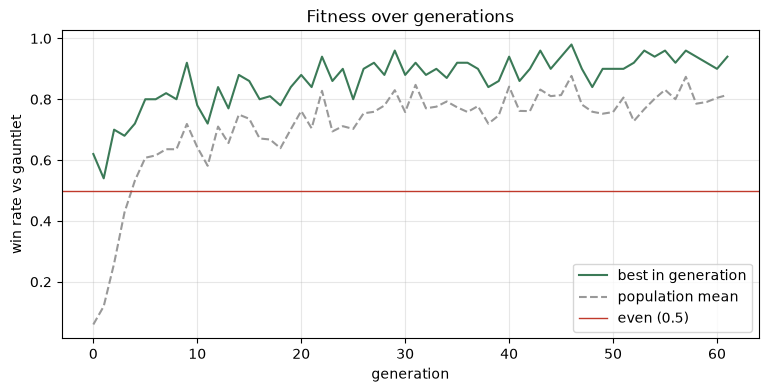

In [11]:
curve = trace.incumbent_curve()
gen_best, gen_mean = [], []
for start_i in range(0, len(trace) - ga.population + 1, ga.population):
    window = [e.estimate.score for e in list(trace)[start_i:start_i + ga.population]]
    gen_best.append(max(window)); gen_mean.append(sum(window) / len(window))

fig, ax = plt.subplots()
ax.plot(gen_best, label="best in generation", color="#3b7a57")
ax.plot(gen_mean, label="population mean", color="#999", linestyle="--")
ax.axhline(0.5, color="#c0392b", linewidth=1, label="even (0.5)")
ax.set_xlabel("generation"); ax.set_ylabel("win rate vs gauntlet")
ax.set_title("Fitness over generations"); ax.legend()
plt.show()

In [12]:
champion = problem.to_decklist(trace.best.vector, "champion")
print(f"in-sample best: {trace.best.score:.3f} over {trace.best.games} games\n")
for name, n in sorted(champion.counts.items(), key=lambda kv: (-kv[1], kv[0])):
    if not n:
        continue
    card = pool.cards[name]
    stats = f"{card.power}/{card.toughness}" if card.is_creature else "land"
    kw = " ".join(sorted(card.keywords))
    print(f"  {n}x {name:<26} {str(card.cost):<9} {stats:<6} {kw}")

in-sample best: 0.980 over 50 games

  18x Forest                     {0}       land   
  4x Daggerback Basilisk        {2}{G}    2/2    Deathtouch
  4x Leatherback Baloth         {G}{G}{G} 4/5    
  4x Ordinary Bear              {3}{G}    4/5    
  3x Llanowar Elves             {G}       1/1    
  3x Terrian, World Tyrant      {2}{G}{G}{G} 9/7    
  2x Ankle Biter                {G}       1/1    Deathtouch
  2x Druid of the Cowl          {1}{G}    1/3    
  2x Moss Viper                 {G}       1/1    Deathtouch
  2x Pheres-Band Centaurs       {4}{G}    3/7    
  2x Snow-Covered Forest        {0}       land   
  1x Boreal Druid               {G}       1/1    
  1x Brushstrider               {1}{G}    3/1    Vigilance
  1x Centaur Courser            {2}{G}    3/3    
  1x Copper Myr                 {2}       1/1    
  1x Elfhame Wurm               {4}{G}    5/4    Trample Vigilance
  1x Gigantosaurus              {G}{G}{G}{G}{G} 10/10  
  1x Gnarled Mass               {1}{G}{G} 3/3  

## 7. The winner's curse

`trace.best` is the highest score *seen during the search*, which is exactly the
number you must not report. Out of thousands of noisy measurements, the maximum is
biased upward — it selects for decks that were good **and** got lucky.

The fix is a fresh measurement on games the search never touched. `stream` is an
index into disjoint families of random numbers, so `stream=999` shares no game
with anything the GA used.

In [13]:
from manalab.search.oracle import Oracle

audit = Oracle(problem, budget=60_000, seed=0)
held_out = audit.evaluate(trace.best.vector, 3_000, stream=999)
lo, hi = held_out.score - 1.96 * held_out.stderr, held_out.score + 1.96 * held_out.stderr

print(f"in-sample (reported by the search) : {trace.best.score:.3f}")
print(f"held out, {held_out.games:,} fresh games      : {held_out.score:.3f}  "
      f"95% CI [{lo:.3f}, {hi:.3f}]")
print(f"\nwinner's curse: {trace.best.score - held_out.score:+.3f}")

in-sample (reported by the search) : 0.980
held out, 3,000 fresh games      : 0.841  95% CI [0.828, 0.854]

winner's curse: +0.139


That gap is not a bug — it is the size of the correction anyone reporting a search
result owes their reader. The held-out number is the real one.

## 8. Did it beat the gauntlet, or overfit to it?

The deeper worry. A deck tuned against five fixed opponents may simply be
well-angled against those five. The test is a gauntlet the search has never seen.

Two checks below: how the champion does against each *individual* gauntlet member,
and how it does against a **held-out gauntlet** built from archetypes that were
never part of the fitness function.

In [14]:
detail = evaluator.evaluate(champion, n_games=3_000, seed=500_000)
print("champion vs each gauntlet deck it was trained against:\n")
for key, value in sorted(detail.metrics.items()):
    if key.startswith("vs:"):
        print(f"  {key[3:]:<12} {value:.3f}")

champion vs each gauntlet deck it was trained against:

  aggro        0.777
  defensive    0.949
  evasion      0.894
  fatties      0.908
  midrange     0.678


In [15]:
# Archetypes deliberately absent from the training gauntlet.
from manalab.evaluate.gauntlet import Archetype

def stats(c):
    return (c.base_power or 0), (c.base_toughness or 0)

HOLDOUT = (
    Archetype("swarm", lands=18, max_cmc=2,
              score=lambda c: stats(c)[0] + stats(c)[1]),
    Archetype("ramp", lands=28,
              score=lambda c: (stats(c)[0] + stats(c)[1]) * (1.0 if c.cmc >= 5 else 0.2)),
    Archetype("tough", lands=22, max_cmc=4,
              score=lambda c: 3.0 * stats(c)[1] - c.cmc),
)
holdout = G.standard(pool, HOLDOUT)
holdout_eval = MatchEvaluator(gauntlet=holdout, cards=pool.cards)

print(f"held-out gauntlet blind spots: {gauntlet_fidelity(holdout) or 'none'}\n")
champ_out = holdout_eval.evaluate(champion, n_games=3_000, seed=700_000)

# A fair reference: how the *training* gauntlet's own best deck does out there.
best_trained = max(rows, key=lambda r: r[1].metrics["win_rate"])[0]
ref_deck = next(d for d in gauntlet if d.name == best_trained)
ref = holdout_eval.evaluate(
    Decklist(dict(Counter(c.name for c in ref_deck.cards)), best_trained),
    n_games=3_000, seed=700_000)

print(f"{'champion':<22} vs held-out gauntlet: {champ_out.metrics['win_rate']:.3f}")
print(f"{best_trained + ' (hand-built)':<22} vs held-out gauntlet: {ref.metrics['win_rate']:.3f}")
for key in sorted(k for k in champ_out.metrics if k.startswith("vs:")):
    print(f"     {key[3:]:<10} champion={champ_out.metrics[key]:.3f}  "
          f"{best_trained}={ref.metrics[key]:.3f}")

held-out gauntlet blind spots: none



champion               vs held-out gauntlet: 0.871
midrange (hand-built)  vs held-out gauntlet: 0.749
     ramp       champion=0.863  midrange=0.825
     swarm      champion=0.874  midrange=0.748
     tough      champion=0.876  midrange=0.673


## 9. Initialisation matters more than the operators

A last experiment, because it is the one that surprised me most while building
this. Over a 132-card pool a random 60-card deck contains a basic land only by
luck, so a cold-start population is mostly decks that cannot cast anything — and
the first thing the GA has to rediscover is that lands exist.

`seed_fraction` grows part of the starting population from a known-sane deck.
Same budget, same operators, different starting point.

In [16]:
sensible = [0] * len(pool.pool.card_ids)
index = {name: i for i, name in enumerate(pool.pool.card_ids)}
sensible[index["Forest"]] = 24
for name in ["Leatherback Baloth", "Kalonian Tusker", "Grizzly Bears",
             "Llanowar Elves", "Centaur Courser", "Alpine Grizzly",
             "Pheres-Band Centaurs", "Gnarled Mass", "Elvish Mystic"]:
    if name in index:
        sensible[index[name]] = 4
sensible = repair(sensible, bounds, size, random.Random(0))

seeded_problem = Problem(pool=pool.pool, evaluator=evaluator, objective=WIN_RATE,
                         start=sensible, name="mono-green/60")

results = {}
for label, fraction in [("cold start", 0.0), ("seeded 25%", 0.25)]:
    opt = GeneticSearch(population=48, games_per_eval=50, workers=workers,
                        seed_fraction=fraction)
    t = run_optimizer(seeded_problem, opt, budget=60_000, seed=1)
    audit2 = Oracle(seeded_problem, budget=20_000, seed=1)
    out = audit2.evaluate(t.best.vector, 2_000, stream=1234)
    results[label] = (t, out)
    print(f"{label:<12} in-sample={t.best.score:.3f}   held-out={out.score:.3f}")

baseline = Oracle(seeded_problem, budget=20_000, seed=1).evaluate(
    tuple(sensible), 2_000, stream=1234)
print(f"{'start deck':<12} {'':>14}   held-out={baseline.score:.3f}   <- what seeding began from")

cold start   in-sample=0.900   held-out=0.749


seeded 25%   in-sample=0.960   held-out=0.837


start deck                    held-out=0.780   <- what seeding began from


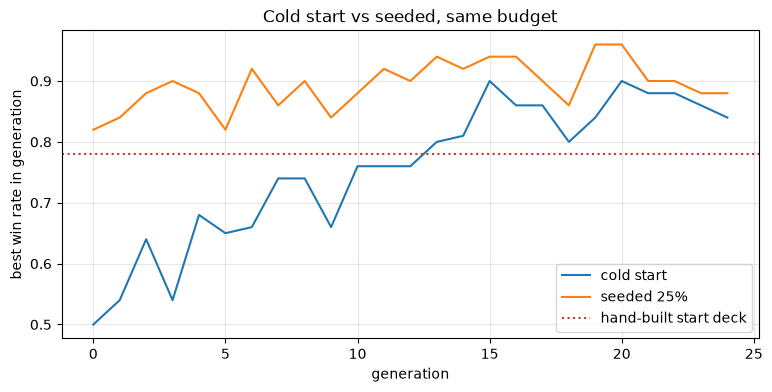

In [17]:
fig, ax = plt.subplots()
for label, (t, _) in results.items():
    gens = []
    for i in range(0, len(t) - 48 + 1, 48):
        gens.append(max(e.estimate.score for e in list(t)[i:i + 48]))
    ax.plot(gens, label=label)
ax.axhline(baseline.score, color="#c0392b", linestyle=":", label="hand-built start deck")
ax.set_xlabel("generation"); ax.set_ylabel("best win rate in generation")
ax.set_title("Cold start vs seeded, same budget"); ax.legend()
plt.show()

## What this does and does not establish

**Established.** The loop works end to end and is reproducible: same seed, same
answer, and the parallel fan-out produces a byte-identical trace to the serial
one. Selection improves a held-out win rate against a fixed gauntlet, and the
champion is a recognisable deck — around twenty lands, mana creatures, and the
most efficient bodies in the pool — rather than a pile of noise.

**Not established.**

1. **That these are good Magic decks.** Both seats are piloted by a heuristic that
   attacks with everything and blocks only when it profits. The search optimises
   win rate against *that pilot*. A deck built to exploit a bad blocker is not the
   same object as a good deck, and nothing here measures the difference.
2. **That the pool is the real pool.** 132 of ~3,200 mono-green cards are modelled
   exactly. The excluded 3,000 are excluded because the engine cannot read them,
   not because they are bad — the best mono-green cards are mostly in that pile.
3. **That the gauntlet is the metagame.** It is five decks, built by the same
   scoring rules from the same pool, so it is closer to five dialects than five
   languages.

**The most valuable next rung** is (1), and it is cheap to test: run the same
champion against a *different* pilot. If its edge survives a change of agent, the
result is about the deck. If it collapses, the search was fitting the agent, and
that is the thing worth knowing before building anything more sophisticated on
top of this.

After that, the ranked list from section 1 says exactly what to implement next —
"rules text the engine does not execute" is one bucket, but the effect-verb layer
already parses those clauses, so the work is wiring verbs to the engine rather
than starting from nothing.